<a href="https://colab.research.google.com/github/superalee11/Tareas-SistemasInteligentes/blob/main/Tarea02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q importlib_resources
!rm -rf /root/tensorflow_datasets/fashion_mnist

In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

In [3]:
def plot_learning_curve(history, titulo=""):
    # Graficar exactitud
    plt.figure()
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title(f'Accuracy Curves {titulo}')
    plt.legend()
    plt.show()

    # Graficar pérdida
    plt.figure()
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'Loss Curves {titulo}')
    plt.legend()
    plt.show()

In [4]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        logical_gpus = tf.config.list_logical_devices('GPU')
        print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
    except RuntimeError as e:
        print(e)

1 Physical GPUs, 1 Logical GPUs


In [5]:
train_ds, test_ds = tfds.load(
    'fashion_mnist',
    split=['train', 'test'],
    shuffle_files=True,
    as_supervised=True,
    batch_size=32,
)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.HBRPOI_3.0.1/fashion_mnist-train.tfrecord-[0-9][0…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.HBRPOI_3.0.1/fashion_mnist-test.tfrecord-[0-9][0-…

Dataset fashion_mnist downloaded and prepared to /root/tensorflow_datasets/fashion_mnist/3.0.1. Subsequent calls will reuse this data.


In [6]:
def a_numpy(ds):
    X, y = [], []
    for imagenes, etiquetas in tfds.as_numpy(ds):
        X.append(imagenes)
        y.append(etiquetas)
    return np.concatenate(X).squeeze(-1), np.concatenate(y)

X_train, y_train = a_numpy(train_ds)
X_test_full, y_test_full = a_numpy(test_ds)

In [7]:
X_test, X_val, y_test, y_val = train_test_split(
    X_test_full, y_test_full, test_size=0.50, random_state=42, stratify=y_test_full
)

X_train.shape, X_test.shape, X_val.shape

((60000, 28, 28), (5000, 28, 28), (5000, 28, 28))

In [8]:
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

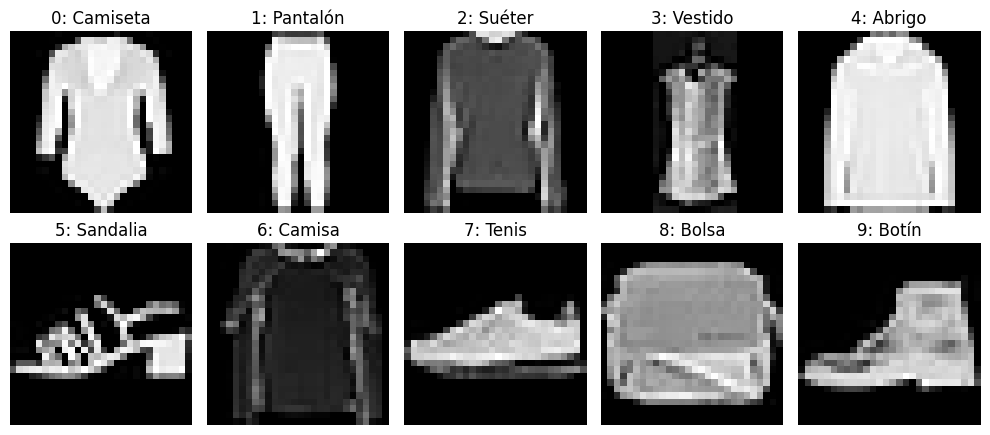

In [9]:
clases = ["Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
          "Sandalia", "Camisa", "Tenis", "Bolsa", "Botín"]

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for c, ax in enumerate(axes.ravel()):
    idx = np.where(y_train == c)[0][0]
    ax.imshow(X_train[idx], cmap="gray", vmin=0, vmax=1.0)
    ax.set_title(f"{c}: {clases[c]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

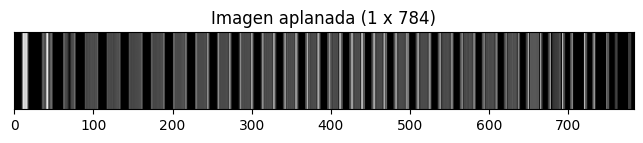

In [10]:
# Flatten convierte la imagen de 28x28 en un vector de 784 valores
plt.figure(figsize=(8, 1))
plt.imshow(X_train[0].ravel().reshape(1, 784), cmap="gray", vmin=0, vmax=1.0, aspect="auto")
plt.yticks([])
plt.title("Imagen aplanada (1 x 784)")
plt.show()

In [11]:
resultados = {}
historias = {}

def entrenar(modelo, nombre, epochs=10):
    modelo.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    history = modelo.fit(
        X_train, y_train,
        epochs=epochs,
        batch_size=32,
        validation_data=(X_val, y_val)
    )
    loss, acc = modelo.evaluate(X_test, y_test, verbose=0)
    resultados[nombre] = {"parámetros": modelo.count_params(),
                          "accuracy entrenamiento": history.history["accuracy"][-1],
                          "accuracy validación": history.history["val_accuracy"][-1],
                          "accuracy prueba": acc}
    historias[nombre] = history
    print(f"\n{nombre} -> accuracy en prueba: {acc:.4f}")
    return history


def graficar_2d(modelo, titulo, n=3000):
    extractor = tf.keras.Model(
        inputs=modelo.inputs,
        outputs=modelo.get_layer("rep_2d").output
    )
    puntos2d = extractor.predict(X_val[:n], verbose=0)

    plt.figure(figsize=(7, 6))
    scatter_plot = plt.scatter(puntos2d[:, 0], puntos2d[:, 1],
                               c=y_val[:n], cmap="tab10", s=10, alpha=0.75)
    barra = plt.colorbar(scatter_plot, ticks=range(10))
    barra.ax.set_yticklabels(clases)
    plt.title(f"Espacio latente 2D: {titulo}")
    plt.xlabel("Neurona de representación 1")
    plt.ylabel("Neurona de representación 2")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()

In [12]:
modelo1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=128, activation="relu"),
    tf.keras.layers.Dense(units=2, activation="linear", name="rep_2d"),
    tf.keras.layers.Dense(units=10, activation="softmax")
], name="config_1")

modelo1.summary()

Model: "config_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_2d (Dense)                  │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,768 (393.62 KB)

 Trainable params: 100,768 (393.62 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history1 = entrenar(modelo1, "Config 1: 128")

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.7033 - loss: 0.8667 - val_accuracy: 0.7736 - val_loss: 0.6661
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8138 - loss: 0.5881 - val_accuracy: 0.8126 - val_loss: 0.5676
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8371 - loss: 0.5107 - val_accuracy: 0.8258 - val_loss: 0.5322
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8486 - loss: 0.4671 - val_accuracy: 0.8338 - val_loss: 0.5089
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8587 - loss: 0.4346 - val_accuracy: 0.8378 - val_loss: 0.4913
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8655 - loss: 0.4087 - val_accuracy: 0.8398 - val_loss: 0.4810
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8719 - loss: 0.3864 - val_accuracy: 0.8428 - val_loss: 0.4706
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8773 - loss: 0.3677 

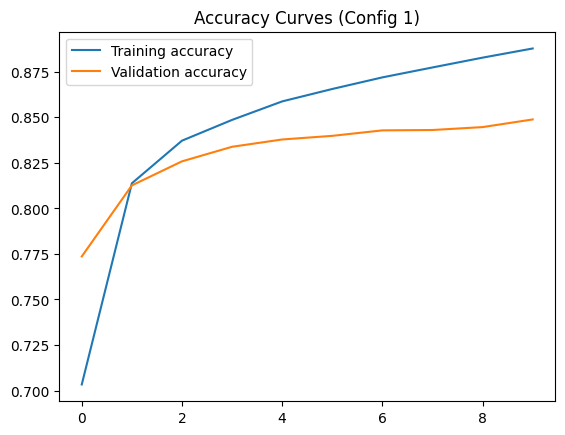

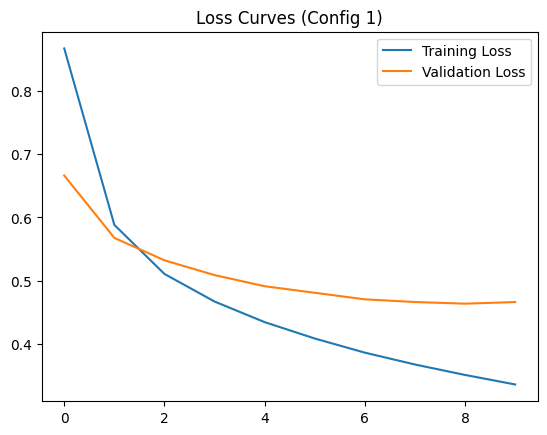

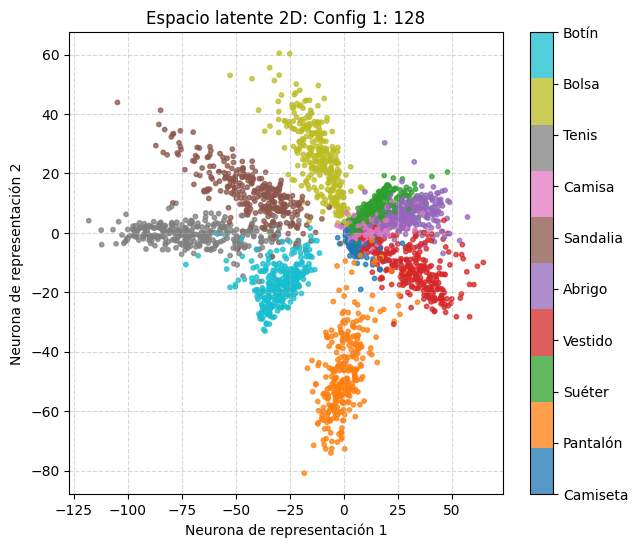

In [14]:
plot_learning_curve(history1, "(Config 1)")
graficar_2d(modelo1, "Config 1: 128")

In [15]:
modelo2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=256, activation="relu"),
    tf.keras.layers.Dense(units=128, activation="relu"),
    tf.keras.layers.Dense(units=64, activation="relu"),
    tf.keras.layers.Dense(units=2, activation="linear", name="rep_2d"),
    tf.keras.layers.Dense(units=10, activation="softmax")
], name="config_2")

modelo2.summary()

Model: "config_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_2d (Dense)                  │ (None, 2)              │           130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,272 (946.38 KB)

 Trainable params: 242,272 (946.38 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
history2 = entrenar(modelo2, "Config 2: 256-128-64")

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.7143 - loss: 0.9440 - val_accuracy: 0.8012 - val_loss: 0.7159
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8395 - loss: 0.5726 - val_accuracy: 0.8304 - val_loss: 0.5938
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8569 - loss: 0.4800 - val_accuracy: 0.8314 - val_loss: 0.5745
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8663 - loss: 0.4329 - val_accuracy: 0.8482 - val_loss: 0.5249
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8760 - loss: 0.3974 - val_accuracy: 0.8522 - val_loss: 0.5117
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8805 - loss: 0.3779 - val_accuracy: 0.8480 - val_loss: 0.5030
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8867 - loss: 0.3522 - val_accuracy: 0.8526 - val_loss: 0.5096
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8910 - loss: 0.3372 -

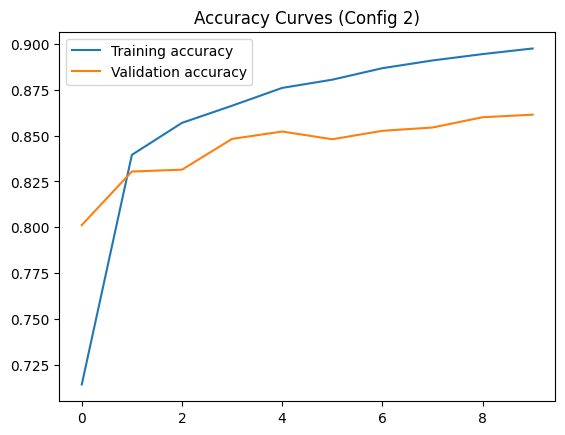

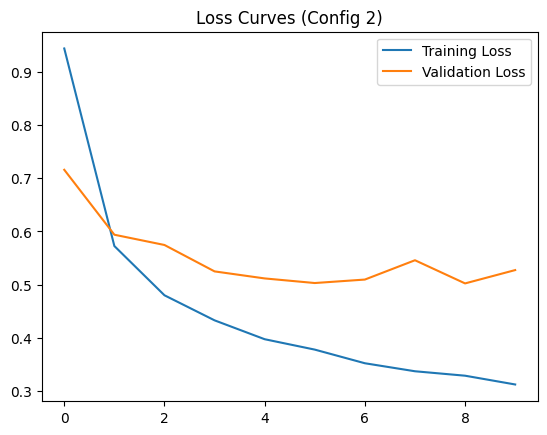

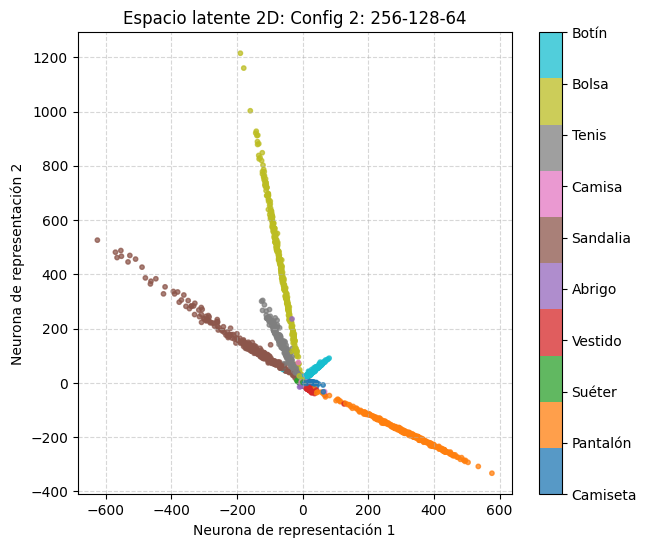

In [17]:
plot_learning_curve(history2, "(Config 2)")
graficar_2d(modelo2, "Config 2: 256-128-64")

In [18]:
modelo3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=256, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(units=128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(units=64, activation="relu"),
    tf.keras.layers.Dense(units=2, activation="linear", name="rep_2d"),
    tf.keras.layers.Dense(units=10, activation="softmax")
], name="config_3")

modelo3.summary()

Model: "config_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_2d (Dense)                  │ (None, 2)              │           130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,272 (946.38 KB)

 Trainable params: 242,272 (946.38 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history3 = entrenar(modelo3, "Config 3: 256-128-64 + Dropout")

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.6819 - loss: 0.9270 - val_accuracy: 0.7676 - val_loss: 0.7047
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7904 - loss: 0.6452 - val_accuracy: 0.8016 - val_loss: 0.5993
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8120 - loss: 0.5781 - val_accuracy: 0.8162 - val_loss: 0.5658
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8289 - loss: 0.5340 - val_accuracy: 0.8294 - val_loss: 0.5323
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8396 - loss: 0.5036 - val_accuracy: 0.8382 - val_loss: 0.5318
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8451 - loss: 0.4834 - val_accuracy: 0.8432 - val_loss: 0.5066
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8470 - loss: 0.4735 - val_accuracy: 0.8422 - val_loss: 0.5017
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8534 - loss: 0.4548 

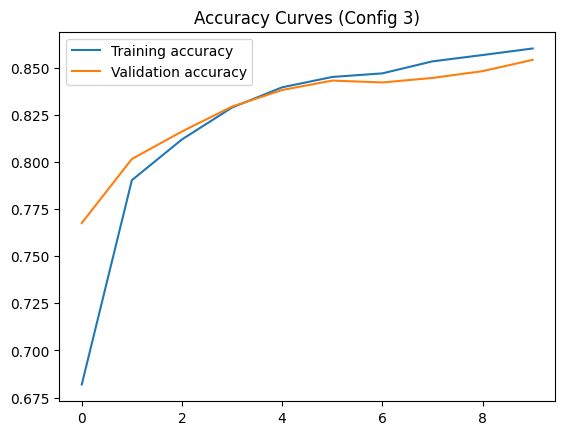

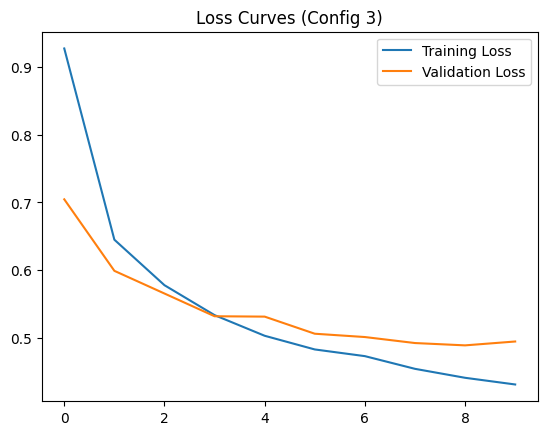

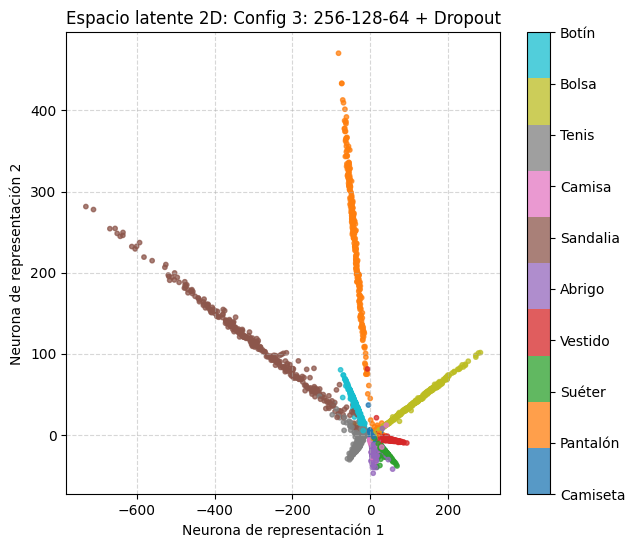

In [20]:
plot_learning_curve(history3, "(Config 3)")
graficar_2d(modelo3, "Config 3: 256-128-64 + Dropout")

In [21]:
tabla = pd.DataFrame(resultados).T
tabla["parámetros"] = tabla["parámetros"].astype(int)
tabla.style.format({"accuracy entrenamiento": "{:.4f}",
                    "accuracy validación": "{:.4f}",
                    "accuracy prueba": "{:.4f}"})

,parámetros,accuracy entrenamiento,accuracy validación,accuracy prueba
Config 1: 128,100768,0.8878,0.8488,0.8634
Config 2: 256-128-64,242272,0.8975,0.8614,0.8688
Config 3: 256-128-64 + Dropout,242272,0.8602,0.8542,0.8652


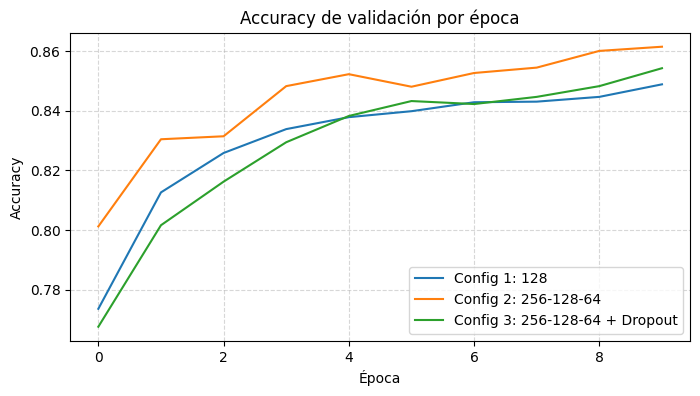

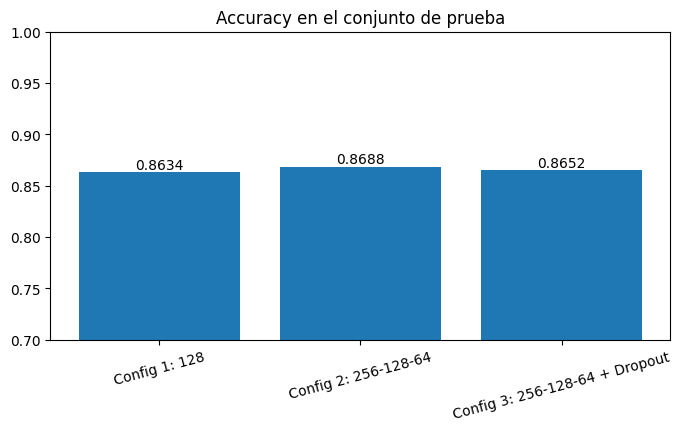

In [22]:
plt.figure(figsize=(8, 4))
for nombre, h in historias.items():
    plt.plot(h.history["val_accuracy"], label=nombre)
plt.title("Accuracy de validación por época")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

plt.figure(figsize=(8, 4))
barras = plt.bar(tabla.index, tabla["accuracy prueba"])
plt.bar_label(barras, fmt="%.4f")
plt.ylim(0.7, 1.0)
plt.title("Accuracy en el conjunto de prueba")
plt.xticks(rotation=15)
plt.show()

Mejor configuración: Config 2: 256-128-64


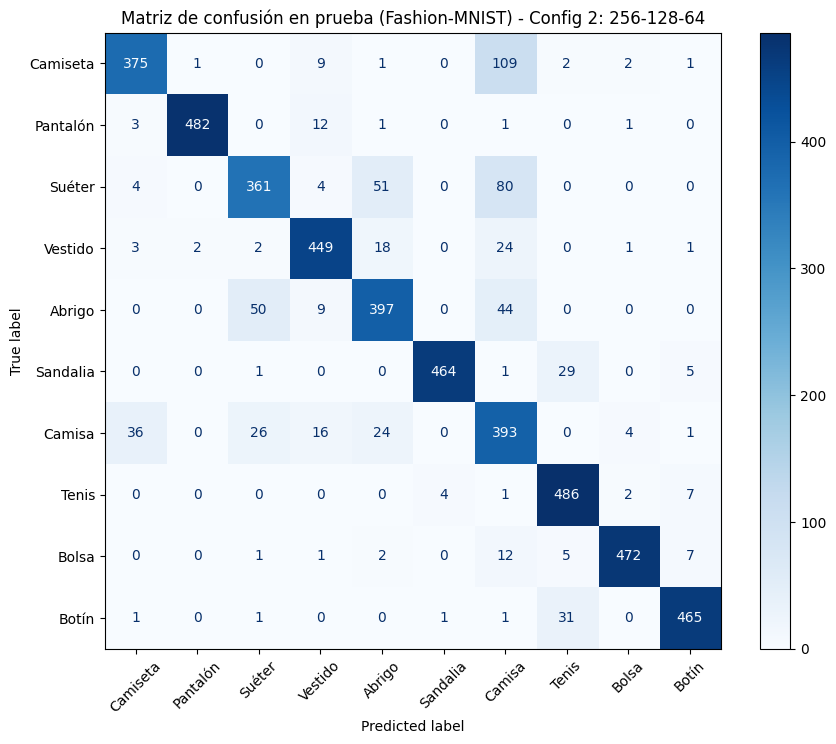

In [23]:
modelos = {"Config 1: 128": modelo1,
           "Config 2: 256-128-64": modelo2,
           "Config 3: 256-128-64 + Dropout": modelo3}
mejor = tabla["accuracy prueba"].astype(float).idxmax()
print("Mejor configuración:", mejor)

y_pred = np.argmax(modelos[mejor].predict(X_test, verbose=0), axis=1)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=clases, cmap="Blues", ax=ax, xticks_rotation=45
)
plt.title(f"Matriz de confusión en prueba (Fashion-MNIST) - {mejor}")
plt.grid(False)
plt.show()